<div style="border-left: 4px solid #9d741c; border-top: 1px solid #8884; border-bottom: 1px solid #8884; padding: 0.75em 1em; margin: 0.5em 0;">

### Principal Component Portfolios of Technology Stocks

---

This project examines the common sources of return variation across 14 technology stocks using a principal-component linear factor model (PCA-LFM). The analysis estimates a lower-dimensional representation of stock returns, examines how much of the cross-sectional variation that representation captures, and interprets the resulting principal-component exposures as factor-mimicking portfolios.

The model is estimated using 2024 daily linear returns and evaluated on 2025 observations through September. Its factor loadings and scaling parameters are learned from the estimation period. The 2025 exercise measures reconstruction of contemporaneously observed returns, rather than a forecast formed before those returns are observed.

The workflow proceeds from market data $\rightarrow$ probability-weighted moment estimation $\rightarrow$ principal components $\rightarrow$ factor construction $\rightarrow$ out-of-sample reconstruction $\rightarrow$ factor exposure interpretation.


**Market and Data:**

The equity universe consists of AAPL, MSFT, GOOGL, AMZN, META, CSCO, NVDA, ORCL, PLTR, SAP, IBM, CRM, SHOP, and UBER. Adjusted closing prices are downloaded through yfinance and converted into daily linear returns. A risk-free instrument is relevant when translating unconstrained factor exposures into fully funded portfolios, but its returns are not modeled separately in this notebook.

Modeling assumptions: A static factor structure estimated in 2024 is used to describe the 2025 market. Its stability is therefore an empirical question rather than an established property of the data.

</div>

In [1]:
import numpy as np
import pandas as pd

import yfinance as yf

from scipy.linalg import eigh
from numpy.linalg import inv

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import plotly.express as px
import plotly.graph_objects as go

plt.style.use('seaborn-v0_8-whitegrid')
np.set_printoptions(precision=6, suppress=True)
pd.options.display.float_format = '{:,.6f}'.format

stock_colors = ['#F72585', "#e7b0c6", "#8333B9", '#3A0CA3', "#516EF1", "#2EA1C5", "#66EBE9", "#2D5751", '#6C6B64', '#48bf53', "#edc350", "#d88546", "#C75757", "#8B1622"]


<div style="border-left: 4px solid #9d741c; border-top: 1px solid #8884; border-bottom: 1px solid #8884; padding: 0.75em 1em; margin: 0.5em 0;">

#### 1. Data Preparation

Adjusted closing prices provide a consistent starting point for comparing equity performance across the 14-stock universe. So I start by downloading the price history, separating observations into a 2024 estimation period and a 2025 evaluation period, and computing each stock's daily linear return, where the vector of daily stock returns is,
$$
X_t = \begin{pmatrix} R_t^{(1)} \\ \vdots \\ R_t^{(14)} \end{pmatrix} \in \mathbb{R}^{14},
$$
where,
$$
R_{t}^{(i)}=\frac{P_t^{(i)}}{P_{t-1}^{(i)}}-1.
$$
This produces the multivariate return series used as the target variables in the factor model. Visualizing the daily returns first helps identify co-movement, unusually large observations, and differences in volatility that motivate the subsequent covariance and correlation analysis.

</div>

In [2]:
# List of technology stock tickers
tickers = sorted(['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'CSCO', 'NVDA', 'ORCL', 'PLTR', 'SAP', 'IBM', 'CRM', 'SHOP', 'UBER'])

# Date range
start_date = pd.Timestamp("2024-01-01")
end_date = pd.Timestamp("2025-09-30") + pd.offsets.BDay(1)   # add 1 business day bc Yahoo's 'end' date is excluded from the download


# --- Daily adjusted closing prices ---
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=False)['Adj Close']


# --- Compute daily linear returns for each stock ---
    # Note: This will be the target variables.
df_x_returns = data.pct_change(fill_method=None).dropna()


# --- Split returns into training and testing data (train on 2024 data, test on 2025 data) ---
df_x_train = df_x_returns.loc[:"2024-12-31"]
df_x_train = pd.DataFrame(df_x_train, index=df_x_train.index, columns=tickers)

df_x_test = df_x_returns.loc["2025-01-01":]
df_x_test = pd.DataFrame(df_x_test, index=df_x_test.index, columns=tickers)

# Convert training and testing dataframes to numpy arrays for later use
x_train = df_x_train.to_numpy()
x_test = df_x_test.to_numpy()


print('Daily Linear Returns (target variables): Training data')
display(df_x_train)

print('Daily Linear Returns (target variables): Testing data')
display(df_x_test)


[*********************100%***********************]  14 of 14 completed

Daily Linear Returns (target variables): Training data


,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Date,,,,,,,,,,,,,,
2024-01-03,-0.007487,-0.009738,-0.016749,0.007781,0.005428,-0.008669,-0.005256,-0.000728,-0.012436,-0.015376,-0.029554,-0.002796,-0.027225,-0.002227
2024-01-04,-0.012700,-0.026268,-0.002382,-0.008513,-0.018212,0.004747,0.007693,-0.007178,0.009019,0.001269,0.009944,-0.008478,0.022278,-0.007725
2024-01-05,-0.004013,0.004634,-0.000478,0.000200,-0.004839,-0.010568,0.013915,-0.000516,0.022897,0.001365,-0.016615,0.008955,0.014846,-0.003806
2024-01-08,0.024175,0.026577,0.038826,0.007387,0.022913,0.012440,0.019065,0.018871,0.064281,0.018787,0.043179,0.018085,0.042679,0.024835
2024-01-09,-0.002263,0.015225,0.001802,-0.010900,0.015197,-0.006578,-0.003429,0.002936,0.016975,-0.009841,-0.016797,-0.002687,0.031149,0.021861
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,0.011478,0.017729,0.004462,0.014751,0.007604,0.011175,0.013170,0.009374,0.003938,0.013421,0.020944,0.019208,0.008513,-0.002586
2024-12-26,0.003176,-0.008732,-0.007868,0.002172,-0.002601,0.002139,-0.007240,-0.002777,-0.002068,0.001575,-0.002913,-0.000513,-0.001997,-0.002431
2024-12-27,-0.013242,-0.014534,-0.009569,-0.006169,-0.014519,-0.009382,-0.005867,-0.017302,-0.020868,-0.015843,-0.037253,-0.013254,-0.016188,-0.006985


Daily Linear Returns (target variables): Testing data


,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Date,,,,,,,,,,,,,,
2025-01-02,-0.026236,0.003783,-0.010977,-0.001689,0.000687,0.000500,0.023449,-0.006928,0.029935,-0.003661,-0.005818,-0.012550,0.011286,0.047248
2025-01-03,-0.002009,0.018027,0.006774,0.002726,0.012458,0.012322,0.008995,0.011396,0.044538,0.001747,0.062508,-0.007075,0.015996,0.022479
2025-01-06,0.006739,0.015255,-0.007119,-0.001529,0.026487,0.000090,0.042290,0.010629,0.034332,-0.003788,-0.049693,0.023405,0.045675,0.026630
2025-01-07,-0.011388,-0.024164,-0.016942,0.002722,-0.007010,0.005793,-0.019534,-0.012808,-0.062170,-0.022090,-0.078109,0.009957,-0.065301,-0.002413
2025-01-08,0.002023,0.000090,0.006063,0.004582,-0.007878,-0.003483,-0.011604,0.005185,-0.000214,0.006851,-0.025146,0.015951,0.008054,-0.018745
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-24,-0.008332,-0.002265,0.005438,-0.003257,-0.017961,-0.017301,0.006963,0.001807,-0.008183,-0.017111,-0.016379,0.013496,-0.007403,-0.000205
2025-09-25,0.018073,-0.009355,-0.020090,0.007873,-0.005463,0.051994,-0.015447,-0.006116,0.004069,-0.055534,-0.002450,-0.023582,-0.036149,-0.001841
2025-09-26,-0.005489,0.007472,0.010293,-0.009285,0.003051,0.010198,-0.006890,0.008737,0.002814,-0.027014,-0.008653,0.005981,-0.022307,0.008709


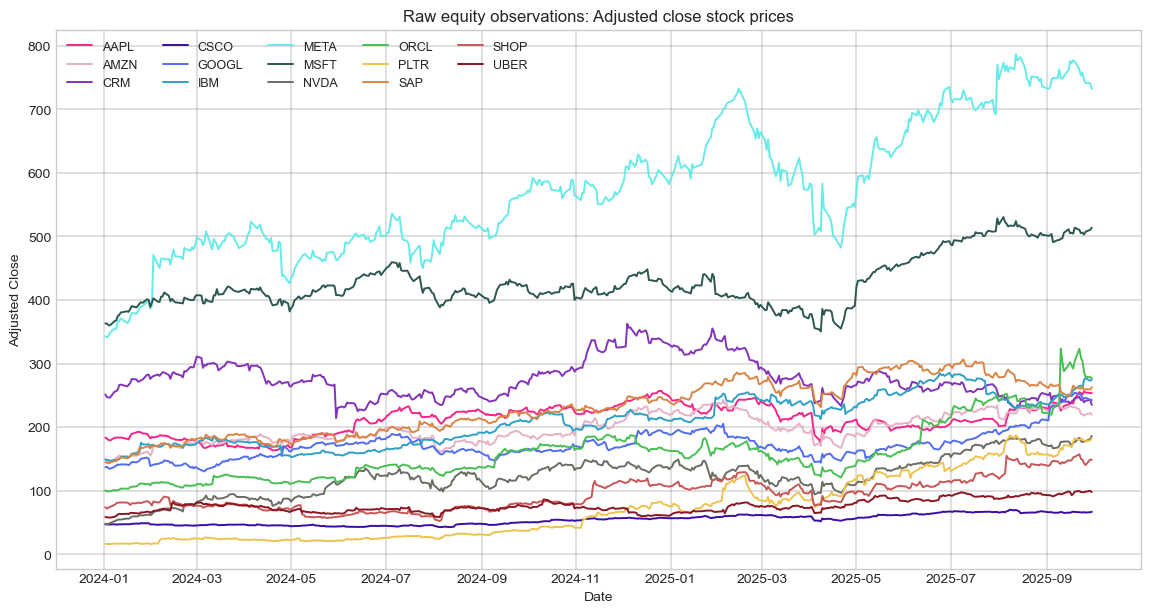

In [3]:
######################### Plot adjusted close data for each stock ########################
fig, ax = plt.subplots(figsize=(14, 7))

for i, stock in enumerate(tickers):
    plt.plot(data.index, data[stock], color=stock_colors[i], linewidth=1.4, label=stock)
    
ax.set(title='Raw equity observations: Adjusted close stock prices', xlabel='Date', ylabel='Adjusted Close')
ax.grid(True, color='dimgrey', lw=0.3)
ax.legend(ncol=5, fontsize=9)
plt.show()


######################### Plot training data linear returns for each stock #######################
fig = go.Figure()

for i, stock in enumerate(tickers):
    fig.add_trace(go.Scatter(x=df_x_train.index, y=df_x_train[stock], marker=dict(color=stock_colors[i]), mode="lines", line=dict(width=1), name=stock))

fig.update_layout(
    title="Daily Linear Returns for Each Stock (Interactive): Training Data",
    xaxis_title="Date",
    yaxis_title="Daily Return",
    template="plotly_white",
    hovermode="x unified"
)
fig.update_xaxes(rangeslider_visible=True)
fig.show()


<div style="padding:15px; border-radius:8px;">
  <b> Notes / Observations: </b><br><br>
  <i> 
  
  The return series exhibit both shared movements and stock-specific variation, suggesting that a common-factor representation may explain part—but not all—of their fluctuations. Some equities have visibly larger daily swings than others, making the choice between covariance-based and volatility-standardized PCA consequential.
  
These plots are descriptive rather than formal tests of stationarity, dependence, or factor stability. The following estimation step uses flexible probabilities to specify how historical observations contribute to the estimated mean and covariance.
  
   </i>
</div>

<div style="border-left: 4px solid #9d741c; border-top: 1px solid #8884; border-bottom: 1px solid #8884; padding: 0.75em 1em; margin: 0.5em 0;">

#### 2. Estimation

Principal-component analysis depends on estimated return moments, so the first modeling decision is how historical observations contribute to the estimation.

The model constructs exponentially time-decaying flexible probabilities over the 2024 equity-return scenarios to estimate the return mean vector and covariance matrix. More recent observations receive greater weight, while older observations retain positive probability.

For a scenario of age $a_t$, where the most recent observation has age zero, the probability is
$$
p_t=\frac{e^{(-(\ln 2)a_t/h)}}{\sum_{s=1}^{T} e^{(-(\ln 2)a_s/h)}},
$$
where $h$ is the half-life measured in trading-observation intervals.

The concentration of these probabilities is summarized by the entropy-based effective number of scenarios:
$$
\operatorname{ENS}(p)= e^{(-\sum_{t=1}^{T}p_t\ln p_t)}.
$$

The model then estimates the probability-weighted 2024 return mean vector and covariance matrix:
$$
\widehat\mu_X=\sum_{t=1}^{T}p_tX_t, \\
\widehat\Sigma_X=\sum_{t=1}^{T} p_t (X_t-\widehat\mu_X)(X_t-\widehat\mu_X)^\top.
$$
These estimated moments provide the statistical inputs for constructing the PCA linear factor model.

**Note:** The current implementation conditions on recency, not market volatility state. State-conditioned and joint time/state-conditioned estimation are potential extensions.

</div>

Number of days (scenarios):  251 and Number of stocks (targets):  14


Date
2024-01-03   0.000740
2024-01-04   0.000749
2024-01-05   0.000757
2024-01-08   0.000765
2024-01-09   0.000774
               ...   
2024-12-24   0.011211
2024-12-26   0.011336
2024-12-27   0.011462
2024-12-30   0.011589
2024-12-31   0.011718
Name: Time-decay probs, Length: 251, dtype: float64

Sum of flexible probabilities: 1.0
Most recent probability weight: 0.01172
Oldest probability weight: 0.00074


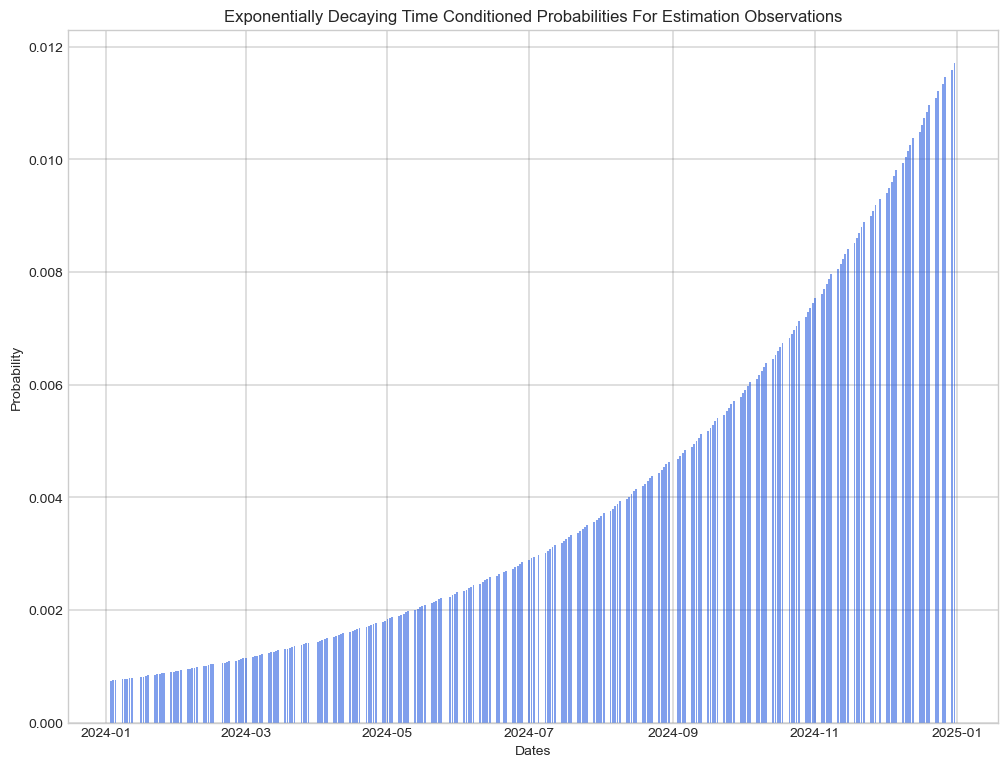

ENS (time cond): 191.8
ENS fraction (time cond):  0.7640254905618538


In [ ]:
# --------------------------------------------------------------------------------------
# Construct a set of time conditioned probabilities for the estimation observations
# -------------------------------------------------------------------------------------

def time_cond_probs(age, half_life, t_bar):
    # Inputs:
        # age = observation/scenario age measured backward from the most recent date (so 0 represents the newest observation) (bc since we are using exponential time decay, we want the recent dates to hold the most weight)
        # half_life = number of observation intervals over which an unnormalized scenario weight falls by half
        # t_bar = number of observations

    if t_bar is not None and len(age) != t_bar:
        raise ValueError('age and t_bar are different lengths.')

    if half_life <= 0:
        raise ValueError('half_life must be greater than zero.')

    # --- Time-decay probabilities ---
    p_decay = np.exp(-np.log(2.0) * age / half_life)   # could also use the following formula but they are equivalent: np.exp(-(np.log(2.0) / half_life) * np.abs(t_bar - np.arange(0, t_bar)))

    # --- Rescaled probabilities ---
    p_decay = p_decay / np.sum(p_decay)

    return p_decay


# --- Params ---
t_bar = df_x_train.shape[0]   # number of days (number of scenarios / time of most recent observation)
n = df_x_train.shape[1]   # number of stocks (number of targets)
print('Number of days (scenarios): ', t_bar, 'and Number of stocks (targets): ', n)


# --- Compute exponentially decaying time probabilities ---
p_decay = time_cond_probs(age=np.arange(t_bar)[::-1], half_life=t_bar/4, t_bar=t_bar)

p_decay_series = pd.Series(p_decay, index=df_x_train.index, name='Time-decay probs')
display(p_decay_series)

# Checks
print("Sum of flexible probabilities:", p_decay_series.sum().round(5))
print("Most recent probability weight:", p_decay_series.iloc[-1].round(5))
print("Oldest probability weight:", p_decay_series.iloc[0].round(5))


############## Plot of probabilities ##############
plt.figure(figsize=(12, 9))

plt.bar(df_x_train.index, p_decay, color="#2C5FE0", alpha=0.6)

plt.title('Exponentially Decaying Time Conditioned Probabilities For Estimation Observations')
plt.xlabel('Dates')
plt.ylabel('Probability')
plt.grid(True, color='dimgrey', lw=0.3)
plt.show()


# -----------------------------------------------
# Compute the effective number of scenarios
# ------------------------------------------------
    # Entropy-based measure of how concentrated the scenario probabilities are.
    # ENS equals T for uniform weights and approaches 1 as weight concentrates on a single observation.

# --- Effective number of scenarios ---
def effective_num_scenarios(p, title):

    ens = np.exp(-(p * np.log(p)).sum())
    print(f'ENS ({title}): {ens:.1f}')
    
    ens_frac = ens / len(p)
    print(f'ENS fraction ({title}): ', ens_frac)

    return ens

ens_p = effective_num_scenarios(p=p_decay, title='time cond')


In [5]:
# -----------------------------------
# Estimated mean and covariance
# ------------------------------------

def hfp_mean_cov(x_train, p):

    # Convert returns and probs to numpy arrays
    x_train = np.asarray(x_train)
    p = np.asarray(p)

    # Check: Make sure lengths are equal
    print('Training returns shape: ', x_train.shape, '\n Probability shape: ', p.shape)

    mu_x = p @ x_train   # estimated HFP joint expectation vector (shape: (n,))

    xc = x_train - mu_x   # centered scenarios/returns around the HFP mean
    print('Centered scenarios shape: ', xc.shape)

    cv_x = (xc.T * p) @ xc   # estimated HFP joint covariance matrix (shape: (n, n)) (could have also computed by: (x_train - mu_x.T).T @ diag(p) @ (x_train - mu_x.T))

    return mu_x, xc, cv_x



# --- Compute estimated mean and covariance of training returns using joint time and state conditioned probabilities ---
mu_x_train, xc_train, cv_x_train = hfp_mean_cov(x_train, p_decay)

df_mu_x = pd.DataFrame(mu_x_train, index=tickers, columns=['Estimated daily training returns mean'])
df_cv_x = pd.DataFrame(cv_x_train, index=tickers, columns=tickers)

display(df_mu_x)
print('Estimated Covariance of Daily Training Returns:')
display(df_cv_x)


Training returns shape:  (251, 14) 
 Probability shape:  (251,)
Centered scenarios shape:  (251, 14)


,Estimated daily training returns mean
AAPL,0.001624
AMZN,0.001792
CRM,0.001917
CSCO,0.001456
GOOGL,0.001580
IBM,0.001157
META,0.001367
MSFT,0.000110
NVDA,0.002253
ORCL,0.001266


Estimated Covariance of Daily Training Returns:


,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
AAPL,0.000168,0.000087,0.000043,0.000027,0.000081,0.000028,0.000083,0.000086,0.000113,0.000059,0.000108,0.000079,0.000113,0.000044
AMZN,0.000087,0.000334,0.000155,0.000083,0.000184,0.000072,0.000199,0.000164,0.000230,0.000165,0.000234,0.000100,0.000286,0.000089
CRM,0.000043,0.000155,0.000505,0.000094,0.000118,0.000102,0.000115,0.000111,0.000232,0.000183,0.000171,0.000154,0.000239,0.000101
CSCO,0.000027,0.000083,0.000094,0.000124,0.000044,0.000064,0.000033,0.000050,0.000076,0.000070,0.000120,0.000038,0.000110,0.000049
GOOGL,0.000081,0.000184,0.000118,0.000044,0.000323,0.000019,0.000166,0.000123,0.000171,0.000068,0.000096,0.000066,0.000175,0.000032
IBM,0.000028,0.000072,0.000102,0.000064,0.000019,0.000200,0.000065,0.000050,0.000078,0.000092,0.000118,0.000060,0.000106,0.000035
META,0.000083,0.000199,0.000115,0.000033,0.000166,0.000065,0.000364,0.000147,0.000230,0.000119,0.000206,0.000117,0.000196,0.000103
MSFT,0.000086,0.000164,0.000111,0.000050,0.000123,0.000050,0.000147,0.000163,0.000172,0.000136,0.000150,0.000093,0.000164,0.000073
NVDA,0.000113,0.000230,0.000232,0.000076,0.000171,0.000078,0.000230,0.000172,0.000918,0.000268,0.000354,0.000189,0.000253,0.000177
ORCL,0.000059,0.000165,0.000183,0.000070,0.000068,0.000092,0.000119,0.000136,0.000268,0.000416,0.000214,0.000130,0.000173,0.000086


<div style="padding:15px; border-radius:8px;">
  <b> Notes / Observations: </b><br><br>
  <i> 
  
The exponentially decaying probability distribution places greater weight on recent observations while retaining all 251 return scenarios from the 2024 estimation period.

The resulting effective number of scenarios is approximately 191.8, or 76.4% of the total observations. This indicates that the estimated mean and covariance place substantially more emphasis on recent observations than a uniform historical estimator.

This weighting reflects an assumption that recent return observations are more relevant to the current dependence structure. It does not guarantee improved estimation accuracy, and the resulting principal components may be sensitive to the chosen half-life.

**Potential extension:** Incorporate market-state conditioning and compare the resulting factor structures with the time-conditioned baseline.
  
   </i>
</div>

<div style="border-left: 4px solid #9d741c; border-top: 1px solid #8884; border-bottom: 1px solid #8884; padding: 0.75em 1em; margin: 0.5em 0;">

#### 3. Model Building

A PCA linear factor model represents the stock-return vector through a smaller number of common factors and a residual component:
$$
X_t = \widehat\mu_X + \widehat\beta \widehat Z_t + U_t.
$$

The model first standardizes the estimated covariance matrix using each stock's estimated volatility. Eigendecomposition of the resulting correlation matrix identifies mutually orthogonal directions of variation in standardized returns. The eigenvalues indicate how much standardized-return variance is associated with each direction, and their cumulative sum provides a factor-count diagnostic.

After choosing the retained dimension $k$, the corresponding eigenvectors are mapped back into the original return coordinates to construct the factor-loading matrix $\beta$ and factor-extraction matrix $\gamma$. These matrices define both the historical factor realizations and the return reconstruction produced by the truncated model.

The factor realizations are then extracted from the actual observed stock returns $X_t$, which gives the principal component factors time series,
$$
\widehat Z_t = \widehat\gamma (X_t - \widehat\mu_X),
$$
where $\widehat\mu_X$ is the estimated mean vector of $X_t$, and $\gamma$ is the factor-extraction weights.

Using the extracted factors, I reconstruct the 2024 stock returns,
$$
\widehat X_t = \widehat\mu_X + \widehat\beta \widehat Z_t.
$$

</div>

sig =  [0.012966 0.018289 0.022462 0.011129 0.017959 0.01415  0.019068 0.012766
 0.030295 0.020399 0.040038 0.014951 0.033929 0.02555 ] 
 with shape:  (14,)
Sigma shape:  (14, 14)
sigma_inv shape:  (14, 14)
Estimated Rescaled Covariance Matrix of Daily Training Returns (correlation matrix):


,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
AAPL,1.000000,0.368895,0.149072,0.184086,0.348771,0.154247,0.336514,0.520432,0.287033,0.224515,0.207606,0.408028,0.257346,0.132582
AMZN,0.368895,1.000000,0.378070,0.407257,0.561664,0.276451,0.569798,0.702942,0.414476,0.441366,0.318913,0.367288,0.460188,0.190712
CRM,0.149072,0.378070,1.000000,0.375512,0.293066,0.320492,0.269374,0.385682,0.341066,0.398380,0.189591,0.458547,0.313937,0.176627
CSCO,0.184086,0.407257,0.375512,1.000000,0.219941,0.404869,0.153646,0.351615,0.224759,0.309551,0.270117,0.229954,0.291751,0.173118
GOOGL,0.348771,0.561664,0.293066,0.219941,1.000000,0.074364,0.483428,0.534939,0.314378,0.184688,0.133937,0.247121,0.286910,0.069323
IBM,0.154247,0.276451,0.320492,0.404869,0.074364,1.000000,0.239384,0.277455,0.181212,0.317344,0.207760,0.282573,0.221732,0.096064
META,0.336514,0.569798,0.269374,0.153646,0.483428,0.239384,1.000000,0.603277,0.398993,0.304747,0.270063,0.410252,0.303184,0.211679
MSFT,0.520432,0.702942,0.385682,0.351615,0.534939,0.277455,0.603277,1.000000,0.444412,0.522989,0.292764,0.489598,0.378093,0.222473
NVDA,0.287033,0.414476,0.341066,0.224759,0.314378,0.181212,0.398993,0.444412,1.000000,0.434450,0.291906,0.416374,0.245838,0.228892
ORCL,0.224515,0.441366,0.398380,0.309551,0.184688,0.317344,0.304747,0.522989,0.434450,1.000000,0.262497,0.425653,0.249453,0.164763


,Eigenvalues
PC1,5.169215
PC2,1.320420
PC3,1.023835
PC4,1.000022
PC5,0.833500
PC6,0.790503
PC7,0.684065
PC8,0.647918
PC9,0.628620
PC10,0.552308


Eigenvectors,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14
AAPL,-0.242225,0.292278,-0.034968,0.102414,-0.426236,0.575340,0.355574,-0.013963,0.019019,0.101458,0.232813,-0.270972,0.088349,0.242444
AMZN,-0.351215,0.157615,0.095651,-0.245753,0.035824,-0.151737,-0.061747,-0.027453,0.175840,-0.131393,-0.126544,-0.023756,-0.681632,0.473292
CRM,-0.263478,-0.281739,0.212941,0.122778,0.468164,-0.028271,0.191843,0.104789,-0.473926,-0.168184,0.277851,-0.436298,-0.035578,0.036165
CSCO,-0.232114,-0.400457,0.195443,-0.359182,-0.050480,0.088579,0.251816,0.472000,0.266496,0.070446,-0.423284,-0.049809,0.253612,-0.002312
GOOGL,-0.260002,0.440151,0.201332,-0.245405,0.197503,-0.093636,0.012806,0.323190,-0.094988,0.059958,0.389077,0.511302,0.245116,0.002458
IBM,-0.200745,-0.462346,0.290930,-0.073095,-0.263837,0.239703,-0.547927,-0.102406,-0.058363,0.288660,0.316437,0.136657,-0.107284,-0.033575
META,-0.301691,0.299351,-0.044812,0.016270,-0.019863,-0.103706,-0.578854,-0.013730,-0.137552,-0.041242,-0.319916,-0.362276,0.439017,0.154083
MSFT,-0.366570,0.199263,0.077503,0.016799,-0.067099,0.031324,-0.030354,-0.022267,0.233544,-0.221260,0.011696,-0.167044,-0.214010,-0.797115
NVDA,-0.276766,0.022223,-0.151190,0.334749,0.045462,-0.370408,0.149110,0.049659,0.064208,0.776142,-0.037874,-0.067182,-0.089667,-0.059291
ORCL,-0.279061,-0.218244,0.101707,0.318717,-0.023070,-0.281527,0.111605,-0.335699,0.492753,-0.308579,0.218882,0.122885,0.339916,0.202611


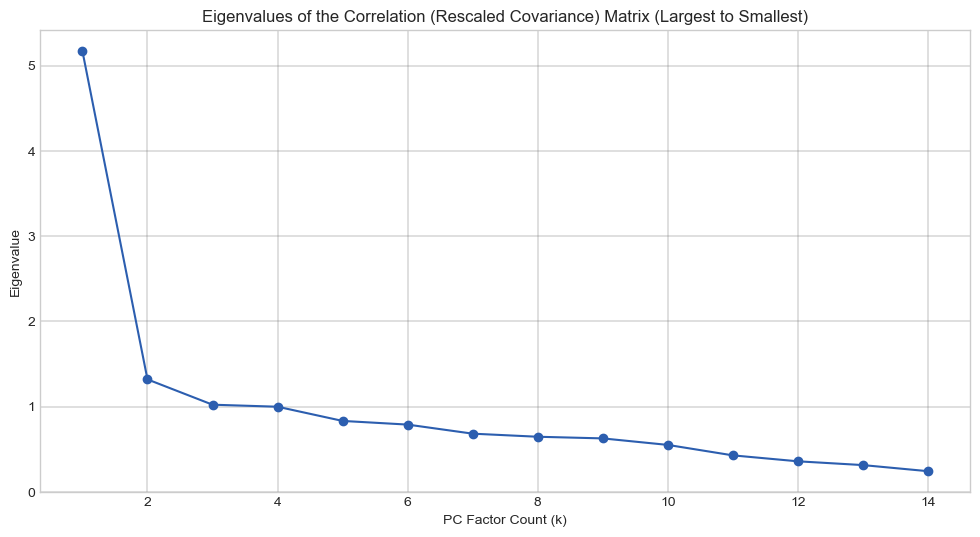

,R^2
PC1,0.369230
PC2,0.463545
PC3,0.536676
PC4,0.608107
PC5,0.667642
PC6,0.724107
PC7,0.772968
PC8,0.819248
PC9,0.864150
PC10,0.903600


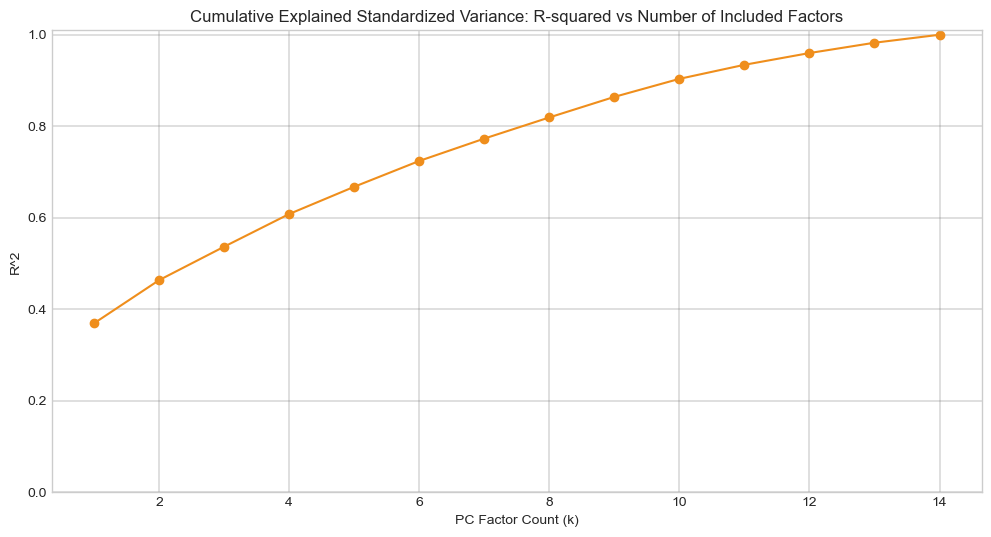

In [6]:
# ----------------------------
# Choose a scale matrix
# ----------------------------
    # Extract individual asset volatilities from the estimated covariance: D = diag(sigma_1, ..., sigma_n).
    # Rescale covariance by D^{-1} to perform PCA on the correlation matrix.
        # Note: This is volatility standardization, not covariance shrinkage.
    # Note: diag() can either take a 1D numpy array and put those values on the diagonal of a nxn matrix with zeros everywhere else, or can extract the diagonal from a 2D array (matrix)

var = np.diag(cv_x_train)   # variance (shape: (n,))

if np.any(var <= 0):
    raise ValueError("All asset variances must be positive.")

sig = np.sqrt(var)      # volatility (shape: (n,))
sigma = np.diag(sig)                    # diagonal volatility matrix shape: (n, n)
sigma_inv = np.diag(1.0 / sig)          # inverse volatility matrix (shape: (n, n))

print('sig = ', sig, '\n with shape: ', sig.shape)
print('Sigma shape: ', sigma.shape)
print('sigma_inv shape: ', sigma_inv.shape)


# --------------------------------------------
# Rescaled covariance to correlation
# -------------------------------------------
    # Here I am performing diagonal rescaling, which converts covariance into correlation by dividing each covariance by its two corresponding standard deviations.
    # The rescaled covariance matrix has a diagonal of ones, so it is also a correlation matrix.
cv_resc = sigma_inv @ cv_x_train @ sigma_inv   # rescaled covariance: sigma^{-1} Cv{X} sigma^{-1} , (shape (n, n))

df_cv_resc = pd.DataFrame(cv_resc, index=tickers, columns=tickers)
print('Estimated Rescaled Covariance Matrix of Daily Training Returns (correlation matrix):')
display(df_cv_resc)


# ---------------------------------------------------------------------------------------
# Compute eigenvalues and eigenvectors of the rescaled covariance (eigendecomp)
# ----------------------------------------------------------------------------------------
lam, e = eigh(cv_resc)   # correlation matrix spectral decomp (eigenvalues (lam) and eigenvectors (e))

# --- Eigenvalues ---
lam = lam[::-1]  # sorted eigenvalues in descending order (shape (n,))

df_lam = pd.DataFrame(lam, index=[f"PC{i+1}" for i in range(n)], columns=['Eigenvalues'])
display(df_lam)


# --- Eigenvectors ---
e = e[:, ::-1]  # sorted eigenvectors in descending order (columns are eigenvectors) (shape (n, n))

df_e = pd.DataFrame(e, index=tickers, columns=[f"PC{i+1}" for i in range(n)])
df_e.columns.name = 'Eigenvectors'
display(df_e)


################################# Plot of eigenvalues ###################################
    # Plot of eigenvalues of the rescaled covariance matrix (largest to smallest)

plt.figure(figsize=(12,6))

plt.plot(np.arange(1, n + 1), lam, marker='o', color='#2c5eaf')

plt.title('Eigenvalues of the Correlation (Rescaled Covariance) Matrix (Largest to Smallest)')
plt.xlabel('PC Factor Count (k)')
plt.ylabel('Eigenvalue')
plt.grid(True, color='dimgrey', lw=0.3)
plt.show()


# -----------------------------------------------------------------------------------
# Compute r-squared for each number of included factors (every k = 1,2,...,n)
# ----------------------------------------------------------------------------------
    # This is computing the cumulative proportion of in-sample standardized variance explained by the leading principal components.
r2_cumvar = np.cumsum(lam) / np.sum(lam)   # r-squared (the cumulative sum of all k from the eigenvalues, rescaled to sum to one)

df_r2_cumvar = pd.DataFrame(r2_cumvar, index=[f"PC{i+1}" for i in range(n)], columns=['R^2'])
display(df_r2_cumvar)


################################ r-squared plot ##################################
plt.figure(figsize=(12,6))

plt.plot(np.arange(1, n + 1), r2_cumvar, marker='o', color='#ef8e1c')

plt.title('Cumulative Explained Standardized Variance: R-squared vs Number of Included Factors')
plt.xlabel('PC Factor Count (k)')
plt.ylabel('R^2')
plt.ylim(0, 1.01)
plt.grid(True, color='dimgrey', lw=0.3)
plt.show()


<div style="padding:15px; border-radius:8px;">
  <b> Notes / Observations: </b><br><br>
  <i> 
  
  The first principal component accounts for approximately 36.92% of total standardized-return variance, and the first two account for 46.35%. Approximately 81.92% is captured by the first eight components. The concentration in the leading direction is consistent with meaningful common variation, but two factors leave more than half of the correlation-scaled variance outside the retained subspace.

Because PCA is performed on the correlation matrix, the decomposition emphasizes variation after standardizing each equity by its estimated volatility. A PCA performed directly on the covariance matrix would generally produce different loadings and factor interpretations.

The currently selected two-factor specification is useful for examining dominant directions but is not yet justified as an optimal factor count. A factor-count rule based on explained variance or a reconstruction criterion would make the truncation decision more systematic.
  
   </i>
</div>

In [7]:
# ---------------------------------
# Choose factor dimensions
# ----------------------------------
k = 2   # factor count (can change)

e_k = e[:, :k]   # first k eigenvectors (shape: (n, k))


# ------------------------------------------------------------------
# Compute optimal loadings and optimal factor-construction matrix
# ------------------------------------------------------------------

# --- Optimal loadings ---
beta = sigma @ e_k   # shape (n, k)

print('Optimal Loadings (beta):')
df_beta = pd.DataFrame(beta, index=tickers, columns=[f"PC{i+1}" for i in range(k)])
display(df_beta)


# --- Optimal factor-construction matrix ---
gamma = e_k.T @ sigma_inv   # shape (k, n)

print('Optimal Factor-Construction Matrix (gamma):')
df_gamma = pd.DataFrame(gamma, index=[f"PC{i+1}" for i in range(k)], columns=tickers)
display(df_gamma)


# ------------------------------------------------------------------------
# Compute the PC factors time series: Z^{PC}_t = gamma (x_t - E{X})
# -------------------------------------------------------------------------
z_pc_train = (gamma @ xc_train.T).T   # shape (t, k)

df_z_pc_train = pd.DataFrame(z_pc_train, index=df_x_train.index, columns=[f"PC{i+1}" for i in range(k)])   # each column contains the PC factor
print('PC Factors Time Series For Training Data:')
display(df_z_pc_train)


# --------------------------------------------------------------------------------------
# Compute the reconstructed in-sample training returns from the factor model 
# -------------------------------------------------------------------------------------
    # This will give the principal component LFM on estimation observations.
x_hat_train = mu_x_train + z_pc_train @ beta.T   # shape (t, n)

df_x_hat_train = pd.DataFrame(x_hat_train, index=df_x_train.index, columns=tickers)
print('Reconstructed In-Sample Returns For 2024:')
display(df_x_hat_train)


# --- Check that my factor extraction and covariance eigendecomp are consistent ---
z_mean = p_decay @ z_pc_train
z_centered = z_pc_train - z_mean

cov_z = (z_centered.T * p_decay) @ z_centered

assert np.allclose(cov_z, np.diag(lam[:k]), atol=1e-10), 'Factor covariance does not match the retained eigenvalues.'
assert np.allclose(gamma @ beta, np.eye(k), atol=1e-10), 'Factor extraction and loading matrices are inconsistent.'


Optimal Loadings (beta):


,PC1,PC2
AAPL,-0.003141,0.003790
AMZN,-0.006423,0.002883
CRM,-0.005918,-0.006328
CSCO,-0.002583,-0.004457
GOOGL,-0.004669,0.007905
IBM,-0.002841,-0.006542
META,-0.005753,0.005708
MSFT,-0.004680,0.002544
NVDA,-0.008385,0.000673
ORCL,-0.005692,-0.004452


Optimal Factor-Construction Matrix (gamma):


,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
PC1,-18.681564,-19.203684,-11.729855,-20.856821,-14.477360,-14.186464,-15.821566,-28.714808,-9.135606,-13.680414,-5.099071,-19.108882,-7.169911,-6.117274
PC2,22.541890,8.618072,-12.542851,-35.983466,24.508336,-32.673586,15.698825,15.609038,0.733554,-10.698982,-4.573212,-3.349818,-1.457895,-6.379489


PC Factors Time Series For Training Data:


,PC1,PC2
Date,,
2024-01-03,1.558676,0.407394
2024-01-04,1.439256,-0.722580
2024-01-05,-0.083075,0.489996
2024-01-08,-4.478890,0.191428
2024-01-09,-0.128880,1.101670
...,...,...
2024-12-24,-2.087406,-0.243841
2024-12-26,0.720378,-0.204864
2024-12-27,3.022005,-0.002291


Reconstructed In-Sample Returns For 2024:


,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Date,,,,,,,,,,,,,,
2024-01-03,-0.001728,-0.007046,-0.009885,-0.004386,-0.002478,-0.005936,-0.005274,-0.006147,-0.010542,-0.009421,-0.007109,-0.005280,-0.010111,-0.009242
2024-01-04,-0.005635,-0.009536,-0.002028,0.000959,-0.010852,0.001796,-0.011037,-0.008463,-0.010302,-0.003711,0.002151,-0.003924,-0.007229,-0.004059
2024-01-05,0.003742,0.003738,-0.000692,-0.000513,0.005841,-0.001813,0.004642,0.001746,0.003279,-0.000443,0.005705,0.001671,0.003301,-0.003030
2024-01-08,0.016416,0.031113,0.027213,0.012173,0.024007,0.012627,0.028226,0.021557,0.039936,0.025909,0.043824,0.020672,0.040084,0.015768
2024-01-09,0.006204,0.005796,-0.004292,-0.003121,0.010890,-0.005685,0.008397,0.003516,0.004075,-0.002905,0.001595,0.001409,0.002652,-0.005394
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,0.007256,0.014497,0.015814,0.007935,0.009400,0.008682,0.011984,0.009258,0.019591,0.014234,0.027467,0.010782,0.021075,0.008031
2024-12-26,-0.001415,-0.003426,-0.001049,0.000508,-0.003403,0.000451,-0.003946,-0.003782,-0.003925,-0.001923,0.004231,-0.001241,-0.002165,-0.003345
2024-12-27,-0.007876,-0.017626,-0.015953,-0.006340,-0.012549,-0.007412,-0.016031,-0.014037,-0.023088,-0.015927,-0.016067,-0.011224,-0.021502,-0.013380


<div style="padding:15px; border-radius:8px;">
  <b> Notes / Observations: </b><br><br>
  <i> 
  
  The model retains the first two principal components to investigate the two dominant directions of standardized return variation. This is an intentionally low-dimensional representation rather than a claim that two factors optimally reconstruct the full return vector.

  The two-factor model uses the leading eigenvectors of the estimated correlation matrix to construct factor loadings and factor exposures. The extracted factor observations are linear combinations of the centered, volatility-standardized stock returns. The fitted values then project the observed returns onto the selected two-dimensional factor subspace.

The first component's eigenvector has entries with a common sign in the current numerical output. Since eigenvector signs are arbitrary, its economic interpretation concerns broad common exposure, not whether a factor is labeled positive or negative. The second component has mixed signs and therefore describes a relative direction among groups of stocks.

In-sample reconstruction isolates the variation represented by the two factors; it does not establish that those factors can predict tomorrow's returns. The next step will test whether the 2024-estimated factor directions remain informative for describing 2025 returns.

**One caution:** The two-factor model can exhibit higher reconstruction performance on a later period even if its training-period explained-variance share is only 46.35%. That is possible because the covariance structure of 2025 differs from the estimated covariance structure of 2024.
  
   </i>
</div>

<div style="border-left: 4px solid #9d741c; border-top: 1px solid #8884; border-bottom: 1px solid #8884; padding: 0.75em 1em; margin: 0.5em 0;">

#### 4. Model Evaluation

The factor loadings, extraction matrix, and weighted mean are estimated from 2024 observations and then held fixed when applied to 2025. For each realized 2025 return vector, the code extracts its contemporaneous factor coordinates and reconstructs returns using the retained factor subspace:
$$
\widehat X_t = \widehat\mu_X + \widehat\beta \widehat Z_t.
$$
Time-series comparisons, actual-versus-reconstructed scatter plots, residual plots, and stock-level $R^2$ values show how well this fixed subspace describes observations from a later period.

**Interpretation:** This is an **out-of-sample reconstruction assessment**, not a genuine forward prediction, because the factors $\widehat Z_t$ are computed from the same day's realized stock returns $R_t$.

</div>

PC Factors Time Series:


,PC1,PC2
Date,,
2025-01-02,0.380757,-0.234151
2025-01-03,-1.823932,-0.212249
2025-01-06,-2.296314,1.935638
2025-01-07,3.388250,-0.539077
2025-01-08,0.092788,-0.225281
...,...,...
2025-09-24,1.047787,0.376928
2025-09-25,1.443333,-1.069610
2025-09-26,0.393888,0.256875


Reconstructed Returns For 2025:


,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Date,,,,,,,,,,,,,,
2025-01-02,-0.000459,-0.001329,0.001146,0.001516,-0.002049,0.001607,-0.002160,-0.002267,-0.001098,0.000141,0.007222,0.000232,0.000688,-0.001866
2025-01-03,0.006548,0.012896,0.014055,0.007114,0.008419,0.007727,0.010648,0.008106,0.017403,0.012593,0.025082,0.009633,0.018848,0.006847
2025-01-06,0.016171,0.022122,0.003258,-0.001239,0.027603,-0.004984,0.025626,0.015780,0.022810,0.005720,0.013197,0.010043,0.019142,-0.000212
2025-01-07,-0.011061,-0.021526,-0.014724,-0.004894,-0.018502,-0.004941,-0.021202,-0.017117,-0.026520,-0.015622,-0.015126,-0.012386,-0.023624,-0.012607
2025-01-08,0.000479,0.000547,0.002794,0.002220,-0.000634,0.002367,-0.000452,-0.000897,0.001323,0.001740,0.009511,0.001455,0.003050,-0.000753
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-24,-0.000239,-0.003852,-0.006669,-0.002930,-0.000333,-0.004285,-0.002509,-0.003834,-0.006279,-0.006377,-0.002710,-0.003075,-0.005844,-0.007075
2025-09-25,-0.006963,-0.010562,0.000144,0.002495,-0.013615,0.004055,-0.013041,-0.009365,-0.010569,-0.002189,0.004661,-0.003681,-0.006681,-0.002630
2025-09-26,0.001360,0.000002,-0.002039,-0.000706,0.001771,-0.001643,0.000568,-0.001079,-0.000877,-0.002120,0.003515,-0.000192,-0.000245,-0.003964


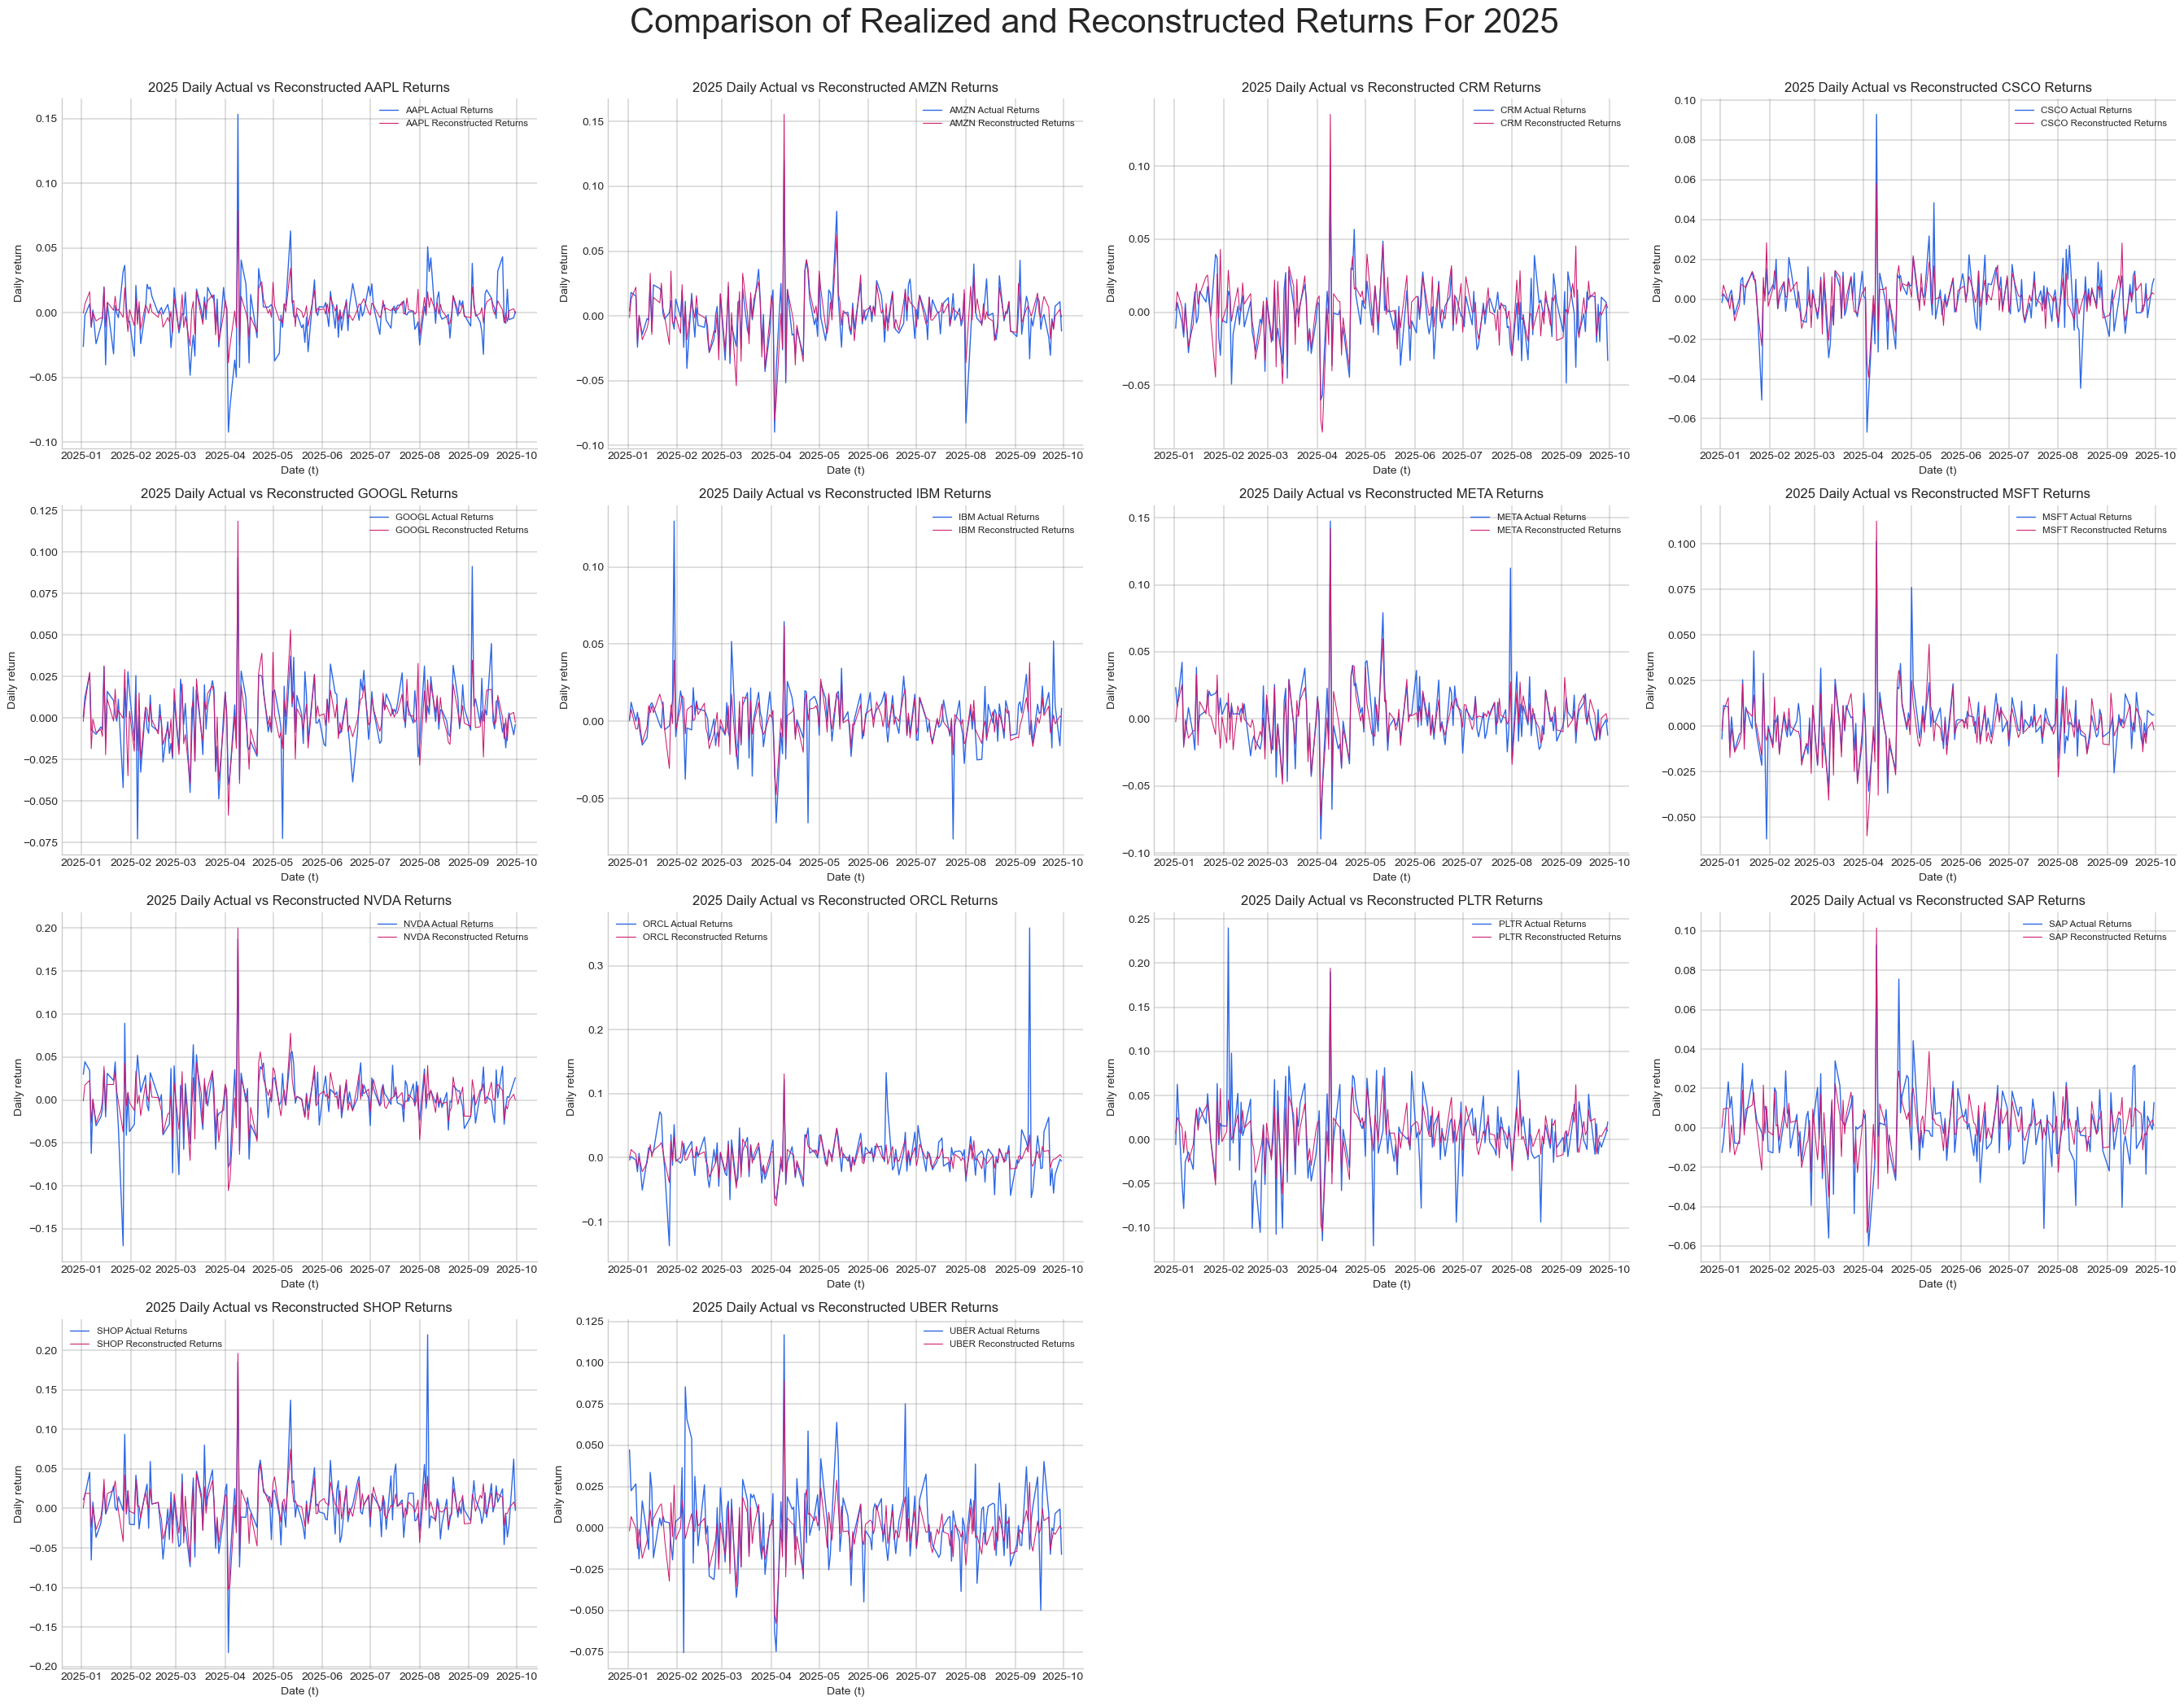

In [8]:
# ----------------------------------------------------------------------
# Apply the PCA factor model estimated on 2024 data to 2025 returns
# ----------------------------------------------------------------------
xc_test = x_test - mu_x_train   # center using training mean
z_pc_test = (gamma @ xc_test.T).T   # PC factors time series on shape (t_test, k)
x_hat_test = mu_x_train + z_pc_test @ beta.T   # fitted / reconstructed returns for 2025 (shape (t_test x n))

df_z_pc_test = pd.DataFrame(z_pc_test, index=df_x_test.index, columns=[f"PC{i+1}" for i in range(k)])   # each column contains the PC factor
print('PC Factors Time Series:')
display(df_z_pc_test)

df_x_hat_test = pd.DataFrame(x_hat_test, index=df_x_test.index, columns=tickers)
print('Reconstructed Returns For 2025:')
display(df_x_hat_test)


############################ Plot of reconstructed vs actual returns ###########################

fig, ax = plt.subplots(nrows=4, ncols=4, figsize=(27, 22), sharex=False, sharey=False)
ax = ax.flatten()

for i, stock in enumerate(tickers):
    ax[i].plot(df_x_test.index, df_x_test[stock], label=f"{stock} Actual Returns", color="#2d68e6", lw=1)
    ax[i].plot(df_x_hat_test.index, df_x_hat_test[stock], label=f"{stock} Reconstructed Returns", color="#CE196D", lw=0.75)

    ax[i].set(title=f'2025 Daily Actual vs Reconstructed {stock} Returns', xlabel='Date (t)', ylabel='Daily return')
    ax[i].grid(True, color='dimgrey', lw=0.3)
    ax[i].legend(fontsize='small')

for j in range(len(tickers), len(ax)):
    ax[j].axis("off")

plt.suptitle('Comparison of Realized and Reconstructed Returns For 2025', size=30)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])   # [left, bottom, right, top]
sns.despine()
plt.show()


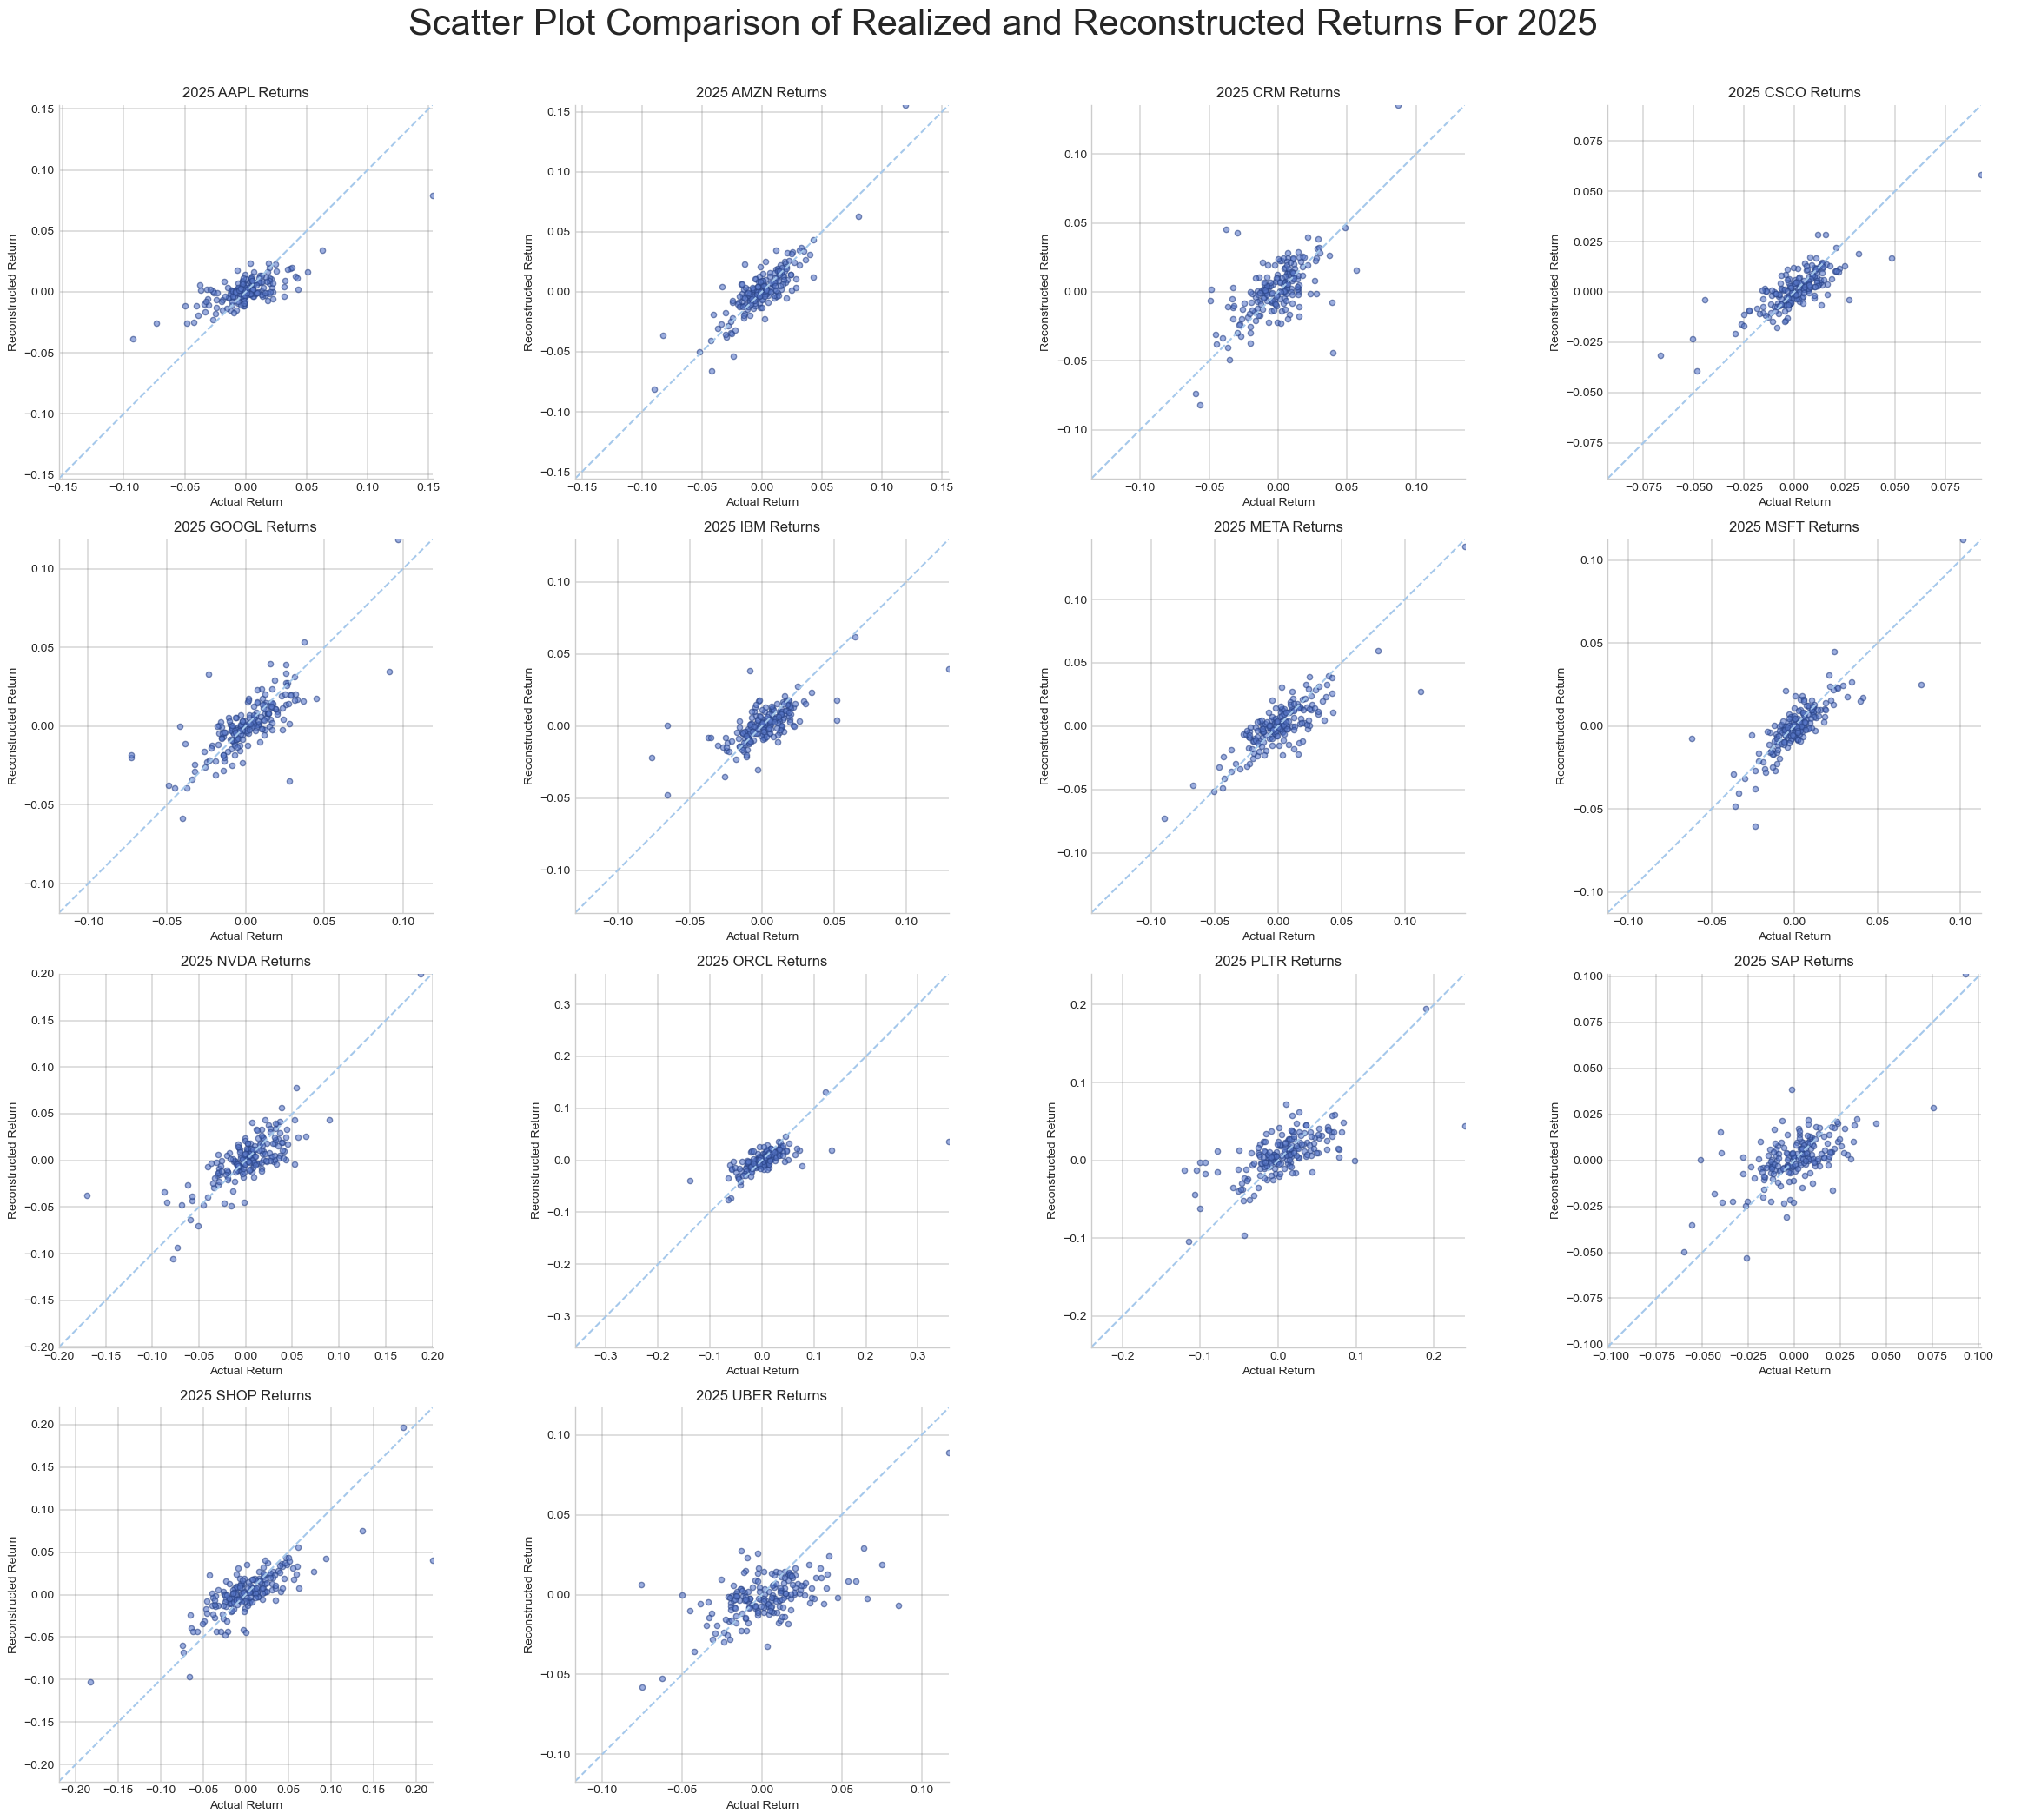

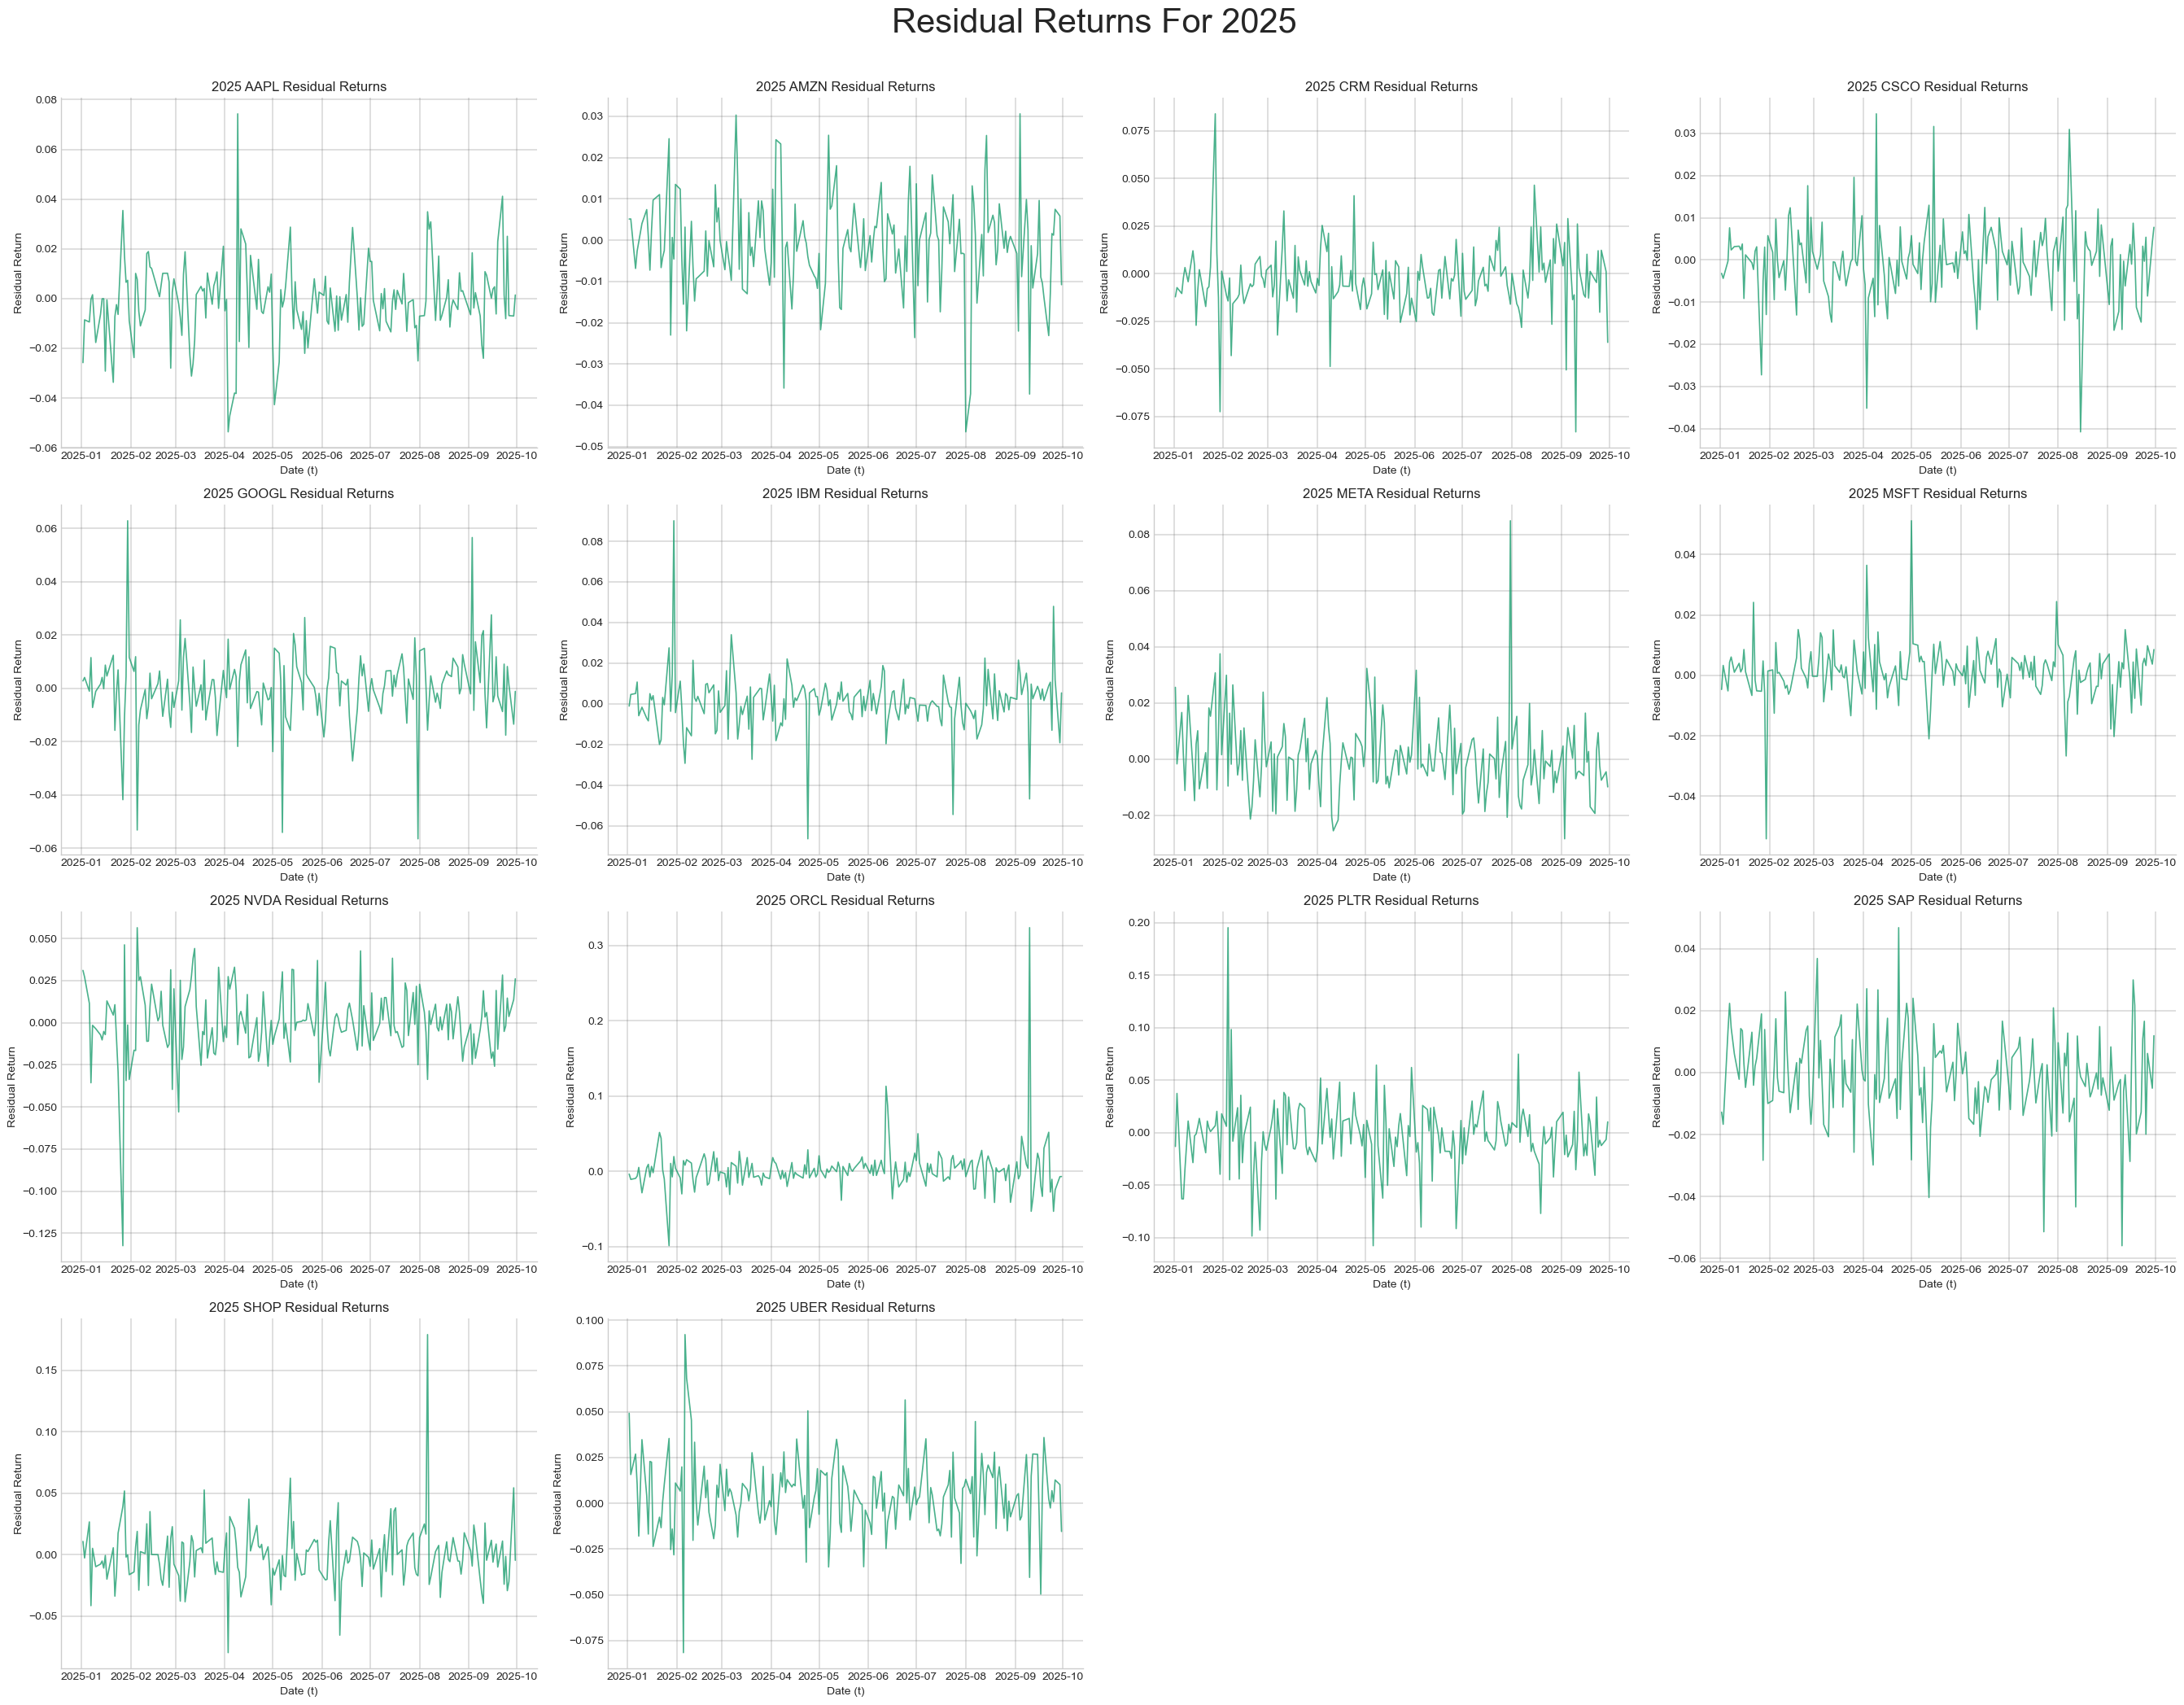

AAPL    0.517579
AMZN    0.721919
CRM     0.204680
CSCO    0.625906
GOOGL   0.563313
IBM     0.476812
META    0.695734
MSFT    0.644850
NVDA    0.617512
ORCL    0.377522
PLTR    0.443488
SAP     0.398065
SHOP    0.613396
UBER    0.299822
Name: Reconstruction R^2, dtype: float64

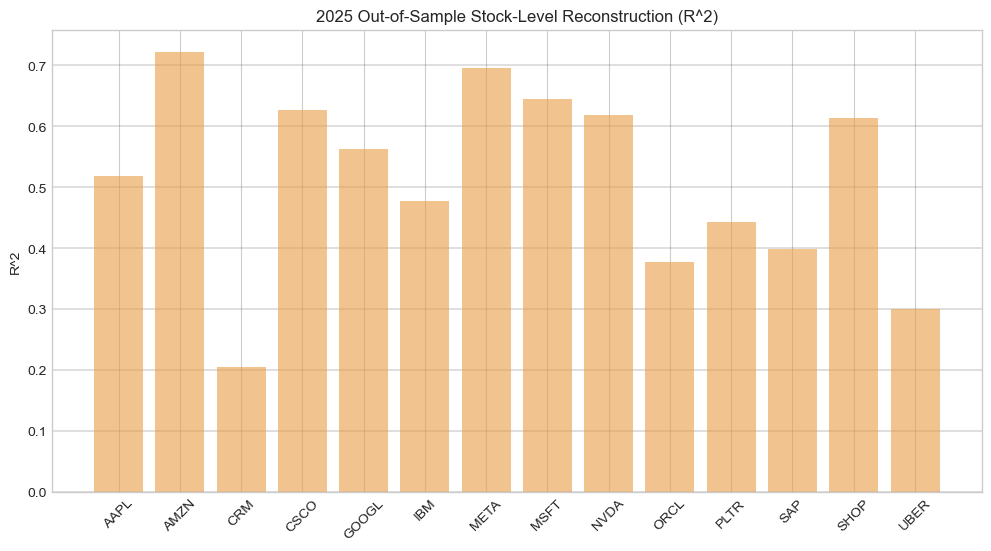

In [9]:
# ------------------------
# Check performance
# -------------------------

######################### Scatter plot of returns ########################
    # Compare realized and reconstructed returns. Points near the 45-degree line indicate small reconstruction errors. Systematic deviations may reveal omitted return variation or model misspecification.

fig, ax = plt.subplots(4, 4, figsize=(24, 22), sharex=False, sharey=False)
ax = ax.flatten()

for i, stock in enumerate(tickers):
    y = df_x_test[stock].values
    y_hat = df_x_hat_test[stock].values
    m = max(abs(y).max(), abs(y_hat).max())

    ax[i].scatter(y, y_hat, color="#5a79ca", edgecolors="#294386", alpha=0.6, s=20)
    ax[i].plot([-m, m], [-m, m], color="#a5c8eb", linestyle='--')   # 45-degree line

    ax[i].set(title=f'2025 {stock} Returns', xlabel='Actual Return', ylabel='Reconstructed Return', xlim=(-m, m), ylim=(-m, m))
    ax[i].set_aspect('equal', adjustable='box')
    ax[i].grid(True, color='dimgrey', lw=0.3)

for j in range(len(tickers), len(ax)):
    ax[j].axis("off")

plt.suptitle('Scatter Plot Comparison of Realized and Reconstructed Returns For 2025', size=30)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
sns.despine()
plt.show()


######################### Plot of testing data residuals (u_t = x_t - x_hat_t) ########################
    # Examine the time variation, clustering, and large realizations of stock returns unexplained by the retained factors.
        # So this is useful for seeing volatility clustering and crisis days.

fig, ax = plt.subplots(4, 4, figsize=(27, 22), sharex=False, sharey=False)
ax = ax.flatten()

for i, stock in enumerate(tickers):
    residual = df_x_test[stock] - df_x_hat_test[stock]

    ax[i].plot(residual.index, residual.values, color="#209f71cf", lw=1.2)

    ax[i].set(title=f'2025 {stock} Residual Returns', xlabel='Date (t)', ylabel='Residual Return')
    ax[i].grid(True, color='dimgrey', lw=0.3)

for j in range(len(tickers), len(ax)):
    ax[j].axis("off")

plt.suptitle('Residual Returns For 2025', size=30)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
sns.despine()
plt.show()


###################### Plot of the reconstruction r-squared of the testing data ######################
    # This is the stock-by-stock reconstruction r-squared across the testing dates.

ss_res = np.sum((x_test - x_hat_test)**2, axis=0)
ss_tot = np.sum((x_test - x_test.mean(axis=0))**2, axis=0)

r2_test = 1.0 - ss_res / ss_tot   # out-of-sample r-squared

df_r2_test = pd.Series(r2_test, index=tickers, name='Reconstruction R^2')
display(df_r2_test)


plt.figure(figsize=(12,6))

plt.bar(x=df_r2_test.index, height=df_r2_test.values, color="#e99c44b4", alpha=0.6)

plt.title('2025 Out-of-Sample Stock-Level Reconstruction (R^2)')
plt.ylabel('R^2')
plt.xticks(rotation=45)
plt.grid(True, axis='y', color='dimgrey', lw=0.3)
plt.show()


<div style="padding:15px; border-radius:8px;">
  <b> Notes / Observations: </b><br><br>
  <i> 
  
  The 2025 comparison reveals how much realized return variation remains aligned with the leading factor directions estimated in 2024. Differences between observed and reconstructed returns are captured by the residuals, which may reflect security-specific behavior, omitted components, and changes in market structure.

Stock-level reconstruction $R^2$ values can vary substantially even when the aggregate explained-variance ratio is moderately high: the factor model describes the joint return structure, not every stock equally well. Individual residual patterns and periods of large reconstruction error are therefore important complements to summary fit statistics.

The fitted return on a 2025 date uses that date's observed return vector to calculate its factor coordinates. Accordingly, strong tracking should not be interpreted as evidence of profitable advance forecasts or a tradable timing signal. A genuine forecasting exercise would require separately modeling the future factor distribution from information available before each forecast date.

The out-of-sample reconstruction $R^2$ results are pretty interesting because AMZN and META have relatively high reconstruction scores, whereas CRM and UBER exhibit substantially more unexplained variation under the two-factor model.
  
   </i>
</div>

<div style="border-left: 4px solid #9d741c; border-top: 1px solid #8884; border-bottom: 1px solid #8884; padding: 0.75em 1em; margin: 0.5em 0;">

#### 5. Factor Portfolio Interpretation

The final step interprets the leading principal components through their factor-extraction weights and corresponding factor returns.

Because PCA is performed on the correlation matrix, rather than directly on the covariance matrix, the eigenvectors $e_j$ identify principal directions of volatility-standardized stock returns. To express these factors as linear combinations of the original stock returns, I use the rows of the factor-extraction matrix:
$$
\widehat\gamma=E_k^\top D^{-1}.
$$
These are the factor-extraction weights associated with the retained principal components.

The factor realization associated with component $j$ is,
$$
\widehat Z_t^{(j)} = \widehat\gamma_j(X_t - \widehat\mu_X).
$$

The extraction weights describe how each stock's centered return contributes to the factor. Their signs and relative magnitudes help interpret the common and contrasting directions of return variation.

These factor series are computed from mean-centered returns and therefore differ from the uncentered returns associated with holding the same stock exposures by a constant mean adjustment.

Furthermore, the extraction weights are not necessarily normalized to represent fully invested equity portfolios. An investable implementation would require explicit portfolio normalization, financing assumptions, and trading constraints.

</div>

PC1 Factor-Extraction Weights Sorted:


,PC1_weights,PC2_weights
PLTR,-5.099071,-4.573212
UBER,-6.117274,-6.379489
SHOP,-7.169911,-1.457895
NVDA,-9.135606,0.733554
CRM,-11.729855,-12.542851
ORCL,-13.680414,-10.698982
IBM,-14.186464,-32.673586
GOOGL,-14.477360,24.508336
META,-15.821566,15.698825
AAPL,-18.681564,22.541890


PC2 Factor-Extraction Weights Sorted:


,PC1_weights,PC2_weights
GOOGL,-14.477360,24.508336
AAPL,-18.681564,22.541890
META,-15.821566,15.698825
MSFT,-28.714808,15.609038
AMZN,-19.203684,8.618072
NVDA,-9.135606,0.733554
SHOP,-7.169911,-1.457895
SAP,-19.108882,-3.349818
PLTR,-5.099071,-4.573212
UBER,-6.117274,-6.379489


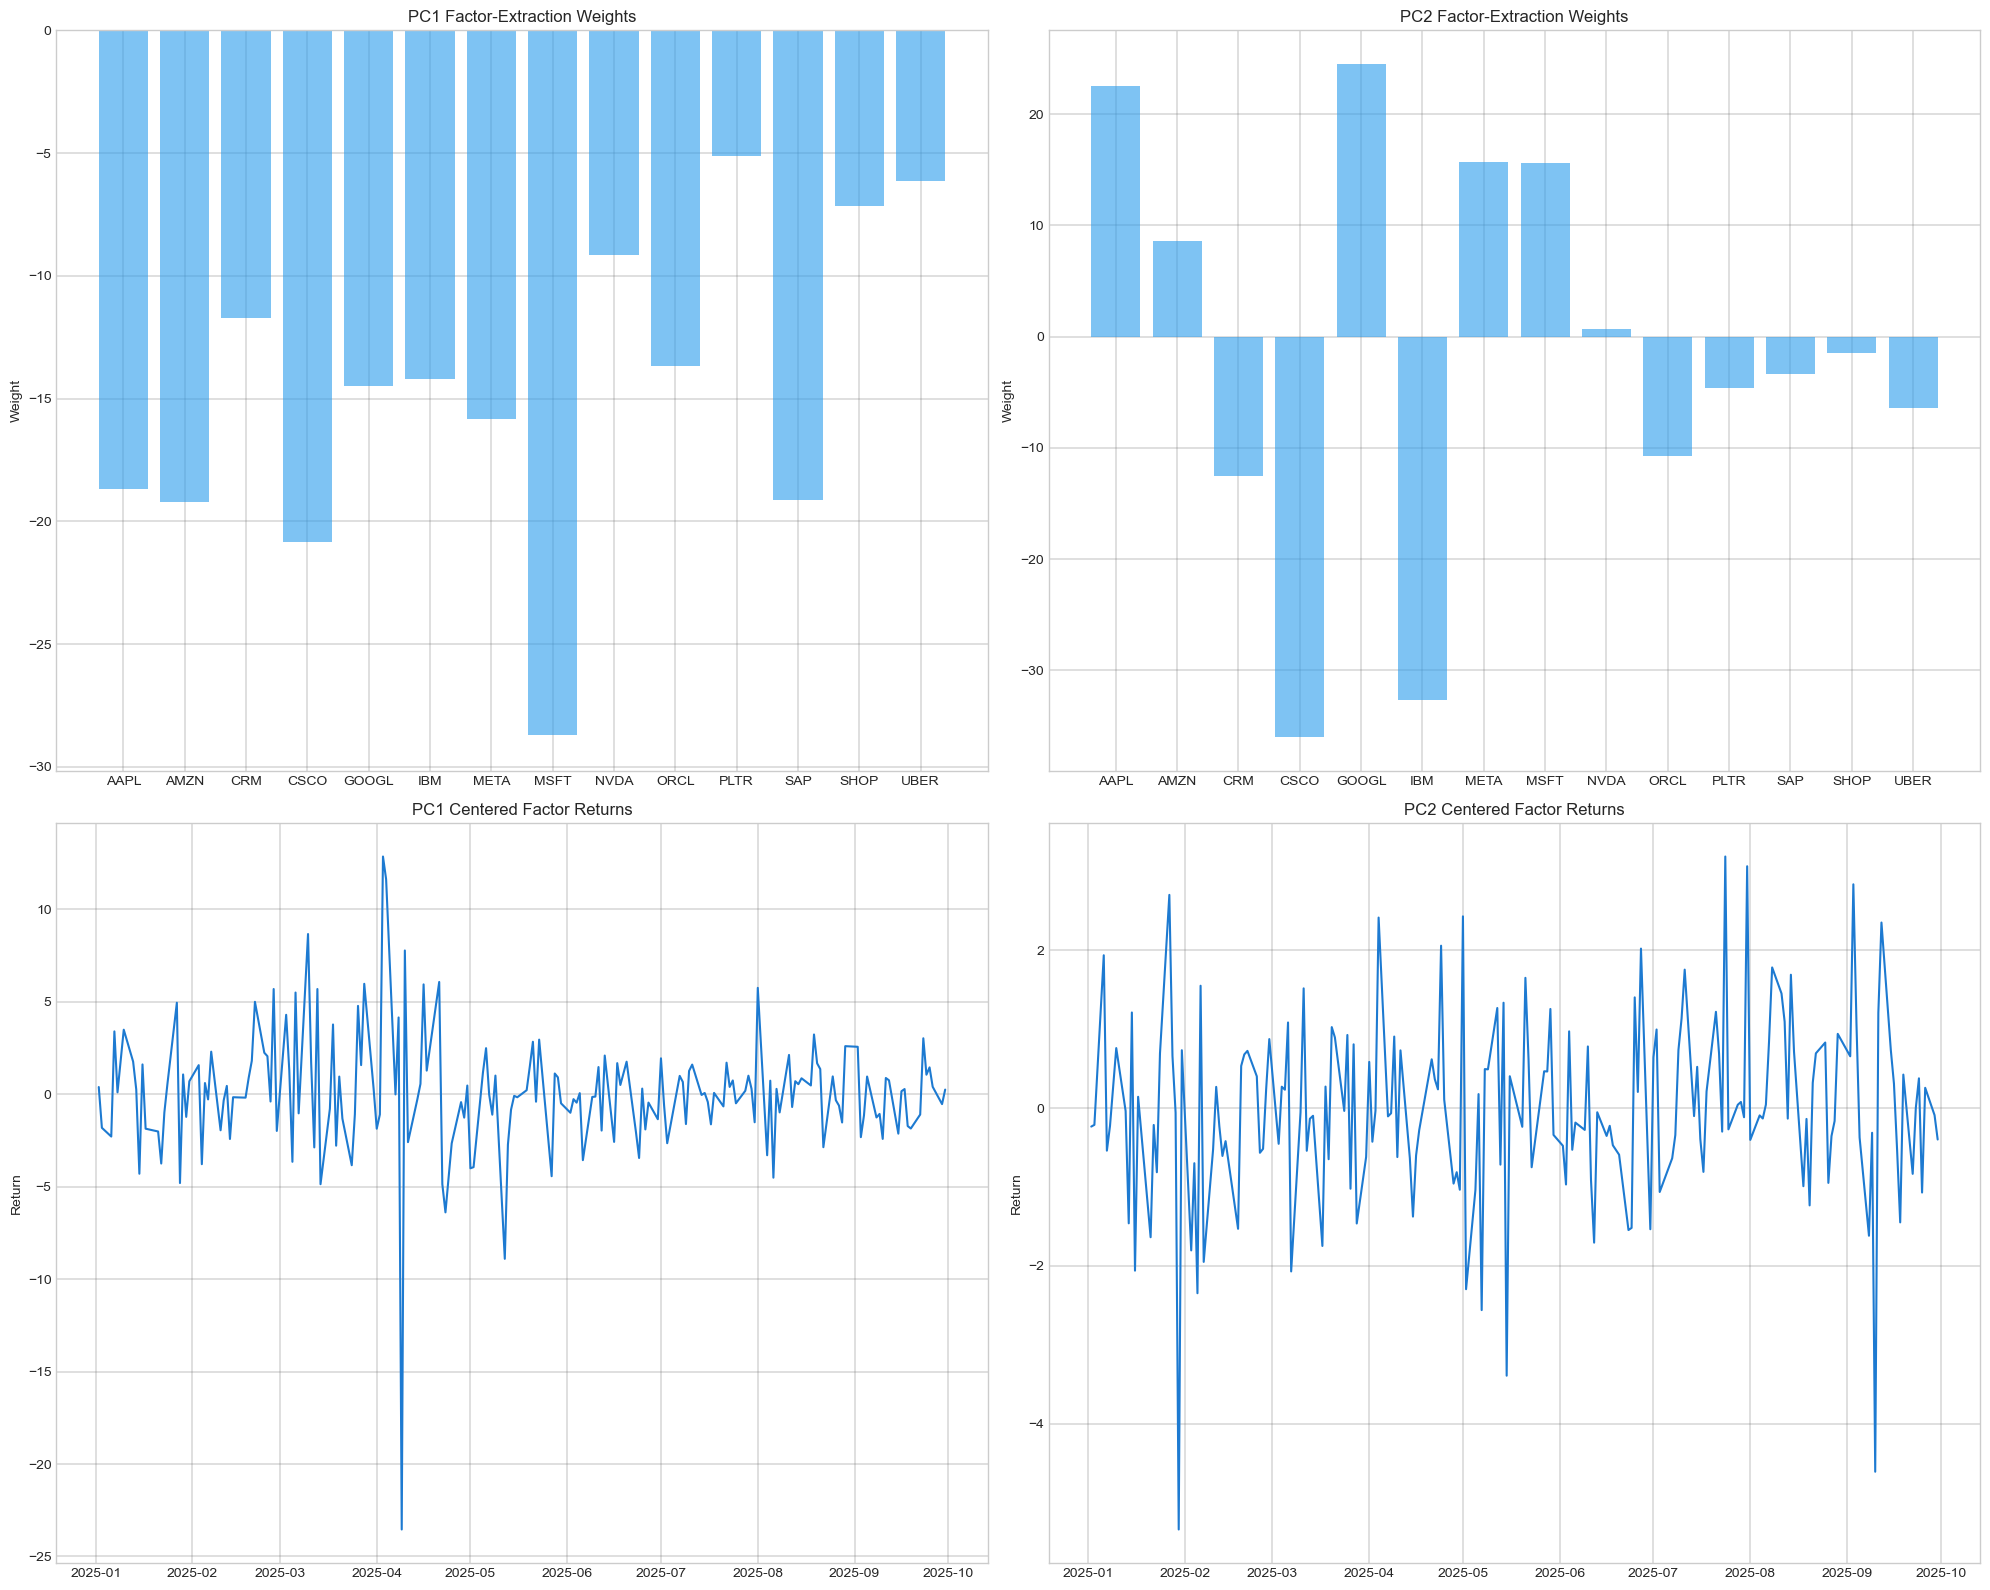

In [10]:
# ---------------------------------------
# Factor-mimicking portfolio weights
# ----------------------------------------
    # Get the rows of the gamma matrix of the first 2 PC factors from z_test (treat each PC factor as a factor portfolio)
    # Since I performed PCA on the correlation matrix, not the covariance matrix, my eigenvectors describe principal directions of standardized returns, not the original stock returns.

# --- Factor-extraction weights ---
    # These are the coefficients applied to stock returns (not percentages of capital invested in each stock).
        # So for each stock, the factor-extraction weight is the coefficient determining the stock's contribution to the PC factor.
w_pc1 = gamma[0, :]
w_pc2 = gamma[1, :]

df_w_pc = pd.DataFrame({'PC1_weights': w_pc1, 'PC2_weights': w_pc2}, index=tickers)

print('PC1 Factor-Extraction Weights Sorted:')
display(df_w_pc.sort_values('PC1_weights', ascending=False))

print('PC2 Factor-Extraction Weights Sorted:')
display(df_w_pc.sort_values('PC2_weights', ascending=False))


############################ Plot of factor-extraction weights and returns ###############################

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(20, 16), sharex=False)

# --- Factor portfolio weights on testing data ---
ax[0, 0].bar(x=df_w_pc.index, height=df_w_pc['PC1_weights'], color="#299becb4", alpha=0.6)
ax[0, 0].set(title='PC1 Factor-Extraction Weights', ylabel='Weight')
ax[0, 0].grid(True, color='dimgrey', lw=0.3)

ax[0, 1].bar(x=df_w_pc.index, height=df_w_pc['PC2_weights'], color="#299becb4", alpha=0.6)
ax[0, 1].set(title='PC2 Factor-Extraction Weights', ylabel='Weight')
ax[0, 1].grid(True, color='dimgrey', lw=0.3)


# --- Daily linear factor portfolio returns on testing data ---
for i in range(k):
    ax[1, i].plot(df_z_pc_test.index, df_z_pc_test[f"PC{i+1}"], color="#1d7ad1ff")
    ax[1, i].set(title=f'PC{i+1} Centered Factor Returns', ylabel='Return')
    ax[1, i].grid(True, color='dimgrey', lw=0.3)

plt.tight_layout()
plt.show()


<div style="padding:15px; border-radius:8px;">
  <b> Notes / Observations: </b><br><br>
  <i> 
  
  The first factor has exposures with a common sign across the 14 stocks, consistent with a broad technology-equity co-movement direction. The overall sign can be reversed without changing the PCA model. The second factor contains both positive and negative exposures, indicating a relative direction that contrasts particular stocks rather than uniformly moving the universe.

The displayed factor series are obtained from contemporaneous 2025 returns and are therefore realized factor exposures, not separately forecast factor returns. Their scale reflects the volatility-standardization convention, so the plotted magnitudes should not be interpreted as percentage returns on a one-dollar, fully invested portfolio without further normalization.

Before using the factors as investable portfolios, the implementation would need a defined budget constraint, treatment of any residual cash or financing position, and transaction-cost assumptions. As constructed, they primarily serve as tools for understanding the structure and concentration of return variation.
  
   </i>
</div>